In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"   # before numpy: small matrices, and bit-reproducible LAPACK

import numpy as np
import matplotlib.pyplot as plt

from core.multilayer_calc import (build_multilayer_graph, default_mu, compute_coarse_phase_diagram,
                                extract_configuration_bank, compute_fine_phase_diagram,
                                time_per_point, layer_measures, classify_phase_diagram,
                                element_types, residual_group, gallery_at, list_classes, symmetry_mismatch)
from core.multilayer_plot import plot_figure_multilayer
from core.cube_calc import symmetry_group

# Supplementary Figure 1: extended multilayer network

Two $5\times 5$ lattices with four sources (Supplementary Note 4), $\mu = 4/46$ such that $N_c/N_g\,\mu = 1$.

A coarse scan collects candidate configurations, which are reduced to one representative per support class modulo $\Gamma \cong D_{2d}$. Then the fine scan starts from every representative at every point and keeps the lowest dissipation.

Both scans save after every row of $\beta$ and resume from the file if interrupted, so rerunning a cell continues where it stopped. Rows run in parallel on `N_JOBS` processes. The result does not depend on `N_JOBS` or on interruptions.

In [2]:
N_JOBS = max(1, (os.cpu_count() or 2) - 1)
SEED = 0

G, pos = build_multilayer_graph()
mu = default_mu(G)
node_perm, edge_perm = symmetry_group(G)
types = element_types(G, pos, node_perm)
print(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges, |Gamma| = {len(edge_perm)}, mu = {mu:.4f}, {N_JOBS} jobs")

n_coarse, n_fine = 50, 120
tag = "seed0"

50 nodes, 105 edges, |Gamma| = 8, mu = 0.0870, 11 jobs


Coarse scan: downward continuation in $\gamma$ from the convex region $\gamma > 1$, at every $\beta$

In [ ]:
coarse_beta = np.linspace(0.2, 2.2, n_coarse)
coarse_gamma = np.linspace(0.4, 1.1, n_coarse)
coarse_path = f"scan_data/coarse_results_multilayer_{n_coarse}_{tag}.npz"

try:
    coarse_results = dict(np.load(coarse_path))
    if not coarse_results["rows_done"].all():
        raise FileNotFoundError  # partial file: let the scan resume it
except FileNotFoundError:
    coarse_results = compute_coarse_phase_diagram(G, pos, mu, coarse_beta, coarse_gamma, path=coarse_path, seed=SEED, n_jobs=N_JOBS)

  50/50 rows, remaining ~0.0 h   


One representative per support class, and an estimate of the fine-scan run time

In [4]:
bank = extract_configuration_bank(coarse_results, G, pos, edge_perm)
t_pt = time_per_point(G, mu, bank)
print(f"bank: {len(bank)} configurations, {t_pt:.1f} s per point, "
      f"fine scan ~{t_pt * n_fine**2 / N_JOBS / 3600:.1f} h on {N_JOBS} jobs")

bank: 392 configurations, 41.2 s per point, fine scan ~15.0 h on 11 jobs


Fine scan: every point tries every configuration of the bank

In [3]:
fine_beta = np.linspace(0.2, 2.2, n_fine)
fine_gamma = np.linspace(0.4, 1.0, n_fine)
fine_path = f"scan_data/fine_results_multilayer_{n_fine}_{tag}.npz"

try:
    fine_results = dict(np.load(fine_path))
    if not fine_results["rows_done"].all():
        raise FileNotFoundError
except FileNotFoundError:
    fine_results = compute_fine_phase_diagram(G, mu, fine_beta, fine_gamma, bank, path=fine_path, n_jobs=N_JOBS)

In [4]:
ACTIVE_TOL = 1e-5                    # edges below this fraction of max k count as inactive
BACKBONE_TOL, SYM_RTOL = ACTIVE_TOL, 1e-4

measures = layer_measures(fine_results, G, pos, active_tol=ACTIVE_TOL)
labels = classify_phase_diagram(fine_results, edge_perm, sym_rtol=SYM_RTOL, support_tol=ACTIVE_TOL)

In [5]:
for r in list_classes(fine_results, labels, types, edge_perm, rtol=SYM_RTOL,
                      support_tol=BACKBONE_TOL, active_tol=ACTIVE_TOL)[:40]:
    print(f"{r['label']:4d}  N*={r['n_edges']:3d}  Gamma*={r['group']:10s} {100*r['fraction']:5.2f} %"
          f"  at gamma={r['gamma']:.2f}, beta={r['beta']:.2f}")

  83  N*= 50  Gamma*=C_1         7.92 %  at gamma=0.53, beta=1.39
   0  N*= 50  Gamma*=C_1         7.37 %  at gamma=0.47, beta=0.54
  79  N*= 51  Gamma*=C_1         7.30 %  at gamma=0.60, beta=1.66
  84  N*= 50  Gamma*=C_1         5.19 %  at gamma=0.55, beta=2.08
  80  N*= 51  Gamma*=C_1         4.80 %  at gamma=0.64, beta=1.02
  85  N*= 50  Gamma*=C_1         4.58 %  at gamma=0.48, beta=2.07
   1  N*= 52  Gamma*=C_1         3.08 %  at gamma=0.58, beta=0.35
   4  N*= 56  Gamma*=C_1         2.40 %  at gamma=0.66, beta=0.20
  78  N*= 51  Gamma*=C_1         1.88 %  at gamma=0.56, beta=0.70
   8  N*= 56  Gamma*=C_1         1.67 %  at gamma=0.68, beta=0.20
  18  N*= 56  Gamma*=C_1         1.67 %  at gamma=0.95, beta=1.53
  56  N*= 56  Gamma*=C_1         1.67 %  at gamma=0.80, beta=0.38
  26  N*= 60  Gamma*=C_1         1.60 %  at gamma=0.98, beta=1.12
  57  N*= 56  Gamma*=C_1         1.48 %  at gamma=0.97, beta=0.38
   6  N*= 56  Gamma*=C_1         1.44 %  at gamma=0.67, beta=0.20
  43  N*= 

Now we pick 10 structurally different classes and prepare the final figure:

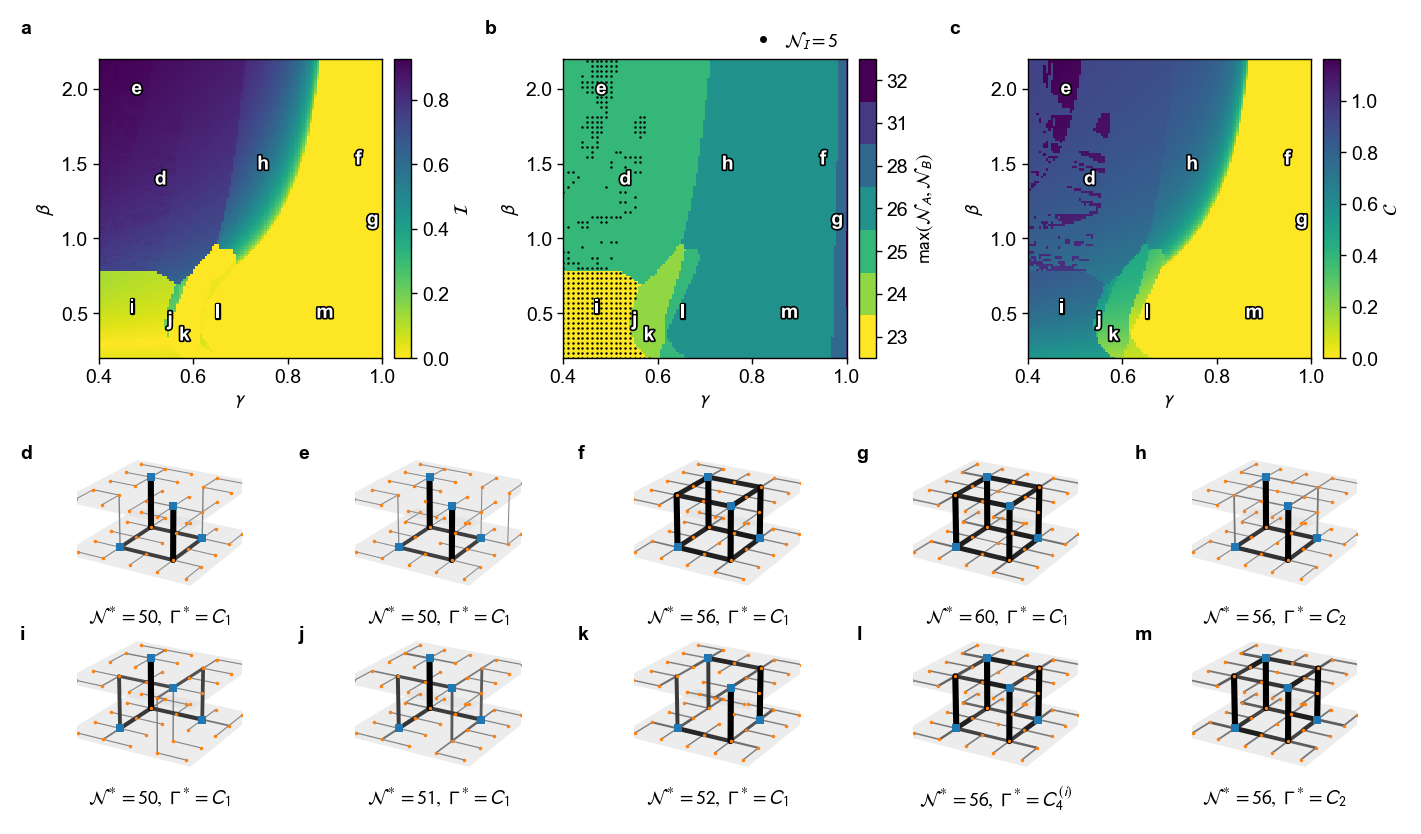

In [ ]:
measures = layer_measures(fine_results, G, pos)

points = [(0.53, 1.39),   # 83: N*=50, C_1  strong fluctuations, small gamma, largest class
          (0.48, 2.00),   # 85: N*=50, C_1, N_I=5, strong fluctuations, small gamma
          (0.95, 1.53),   # 18: N*=56, C_1  strong fluctuations, gamma near 1
          (0.98, 1.12),   # 26: N*=60, C_1  most connected class in the list
          (0.75, 1.50),   # 66: N*=56, Gamma*=C_2, N_I=4
          (0.47, 0.54),   #  0: N*=50, C_1  weak fluctuations, small gamma
          (0.55, 0.45),   # 53: N*=51, Gamma*=C_1, N_I=4
          (0.58, 0.35),   #  1: N*=52, C_1  weak fluctuations, intermediate gamma
          (0.65, 0.50),   # 64: N*=56, C_4^(i)
          (0.88, 0.50)]   # 66: N*=56, C_2

gallery = gallery_at(fine_results, points, active_tol=ACTIVE_TOL)
fig, info = plot_figure_multilayer(fine_results, measures, gallery, G, pos, types, edge_perm,
                                   savepath="FigureS_multilayer.pdf", sym_rtol=SYM_RTOL,
                                   sym_support_tol=BACKBONE_TOL, active_tol=ACTIVE_TOL,
                                   inter_style="stipple", stipple_stride=2, stipple_size=0.8, n_col=5)
plt.show()

Symmetry mismatch

In [14]:
for (letter, *_), p in zip(info, gallery):
    print(letter, [(t, f"{d:.0e}", n) for t, d, n in symmetry_mismatch(p["k"], types, edge_perm)])

d [('sigma_d', '7e-03', 12), ('sigma_d', '2e-03', 20), ('C2', '7e-03', 28), ('S4', '9e-01', 26), ("C2'", '9e-01', 28), ('S4', '9e-01', 26), ("C2'", '9e-01', 28)]
e [('sigma_d', '3e-03', 24), ('sigma_d', '8e-04', 20), ('C2', '3e-03', 24), ('S4', '1e+00', 36), ("C2'", '1e+00', 32), ('S4', '1e+00', 36), ("C2'", '1e+00', 36)]
f [('sigma_d', '7e-02', 20), ('sigma_d', '7e-02', 20), ('C2', '7e-02', 8), ('S4', '7e-02', 12), ("C2'", '7e-02', 16), ('S4', '7e-02', 12), ("C2'", '6e-02', 8)]
g [('sigma_d', '1e-01', 8), ('sigma_d', '1e-01', 16), ('C2', '1e-01', 8), ('S4', '1e-01', 8), ("C2'", '1e-01', 8), ('S4', '1e-01', 8), ("C2'", '1e-01', 8)]
h [('sigma_d', '3e-02', 24), ('sigma_d', '3e-02', 24), ('C2', '6e-15', 0), ('S4', '8e-01', 8), ("C2'", '8e-01', 16), ('S4', '8e-01', 8), ("C2'", '8e-01', 16)]
i [('sigma_d', '9e-01', 48), ('sigma_d', '2e-01', 20), ('C2', '9e-01', 36), ('S4', '6e-01', 30), ("C2'", '6e-01', 24), ('S4', '6e-01', 30), ("C2'", '6e-01', 24)]
j [('sigma_d', '6e-01', 30), ('sigma_d'

Print parameters for figure caption

In [16]:
print(", ".join(rf"\textbf{{{l}}} ({g:.2f}, {b:.2f})" for l, _, _, g, b in info))

\textbf{d} (0.53, 1.39), \textbf{e} (0.48, 2.00), \textbf{f} (0.95, 1.53), \textbf{g} (0.98, 1.12), \textbf{h} (0.75, 1.49), \textbf{i} (0.47, 0.54), \textbf{j} (0.55, 0.45), \textbf{k} (0.58, 0.35), \textbf{l} (0.65, 0.50), \textbf{m} (0.88, 0.50)


How many interlayer edges are there?

In [15]:
vals, counts = np.unique(measures["n_inter"], return_counts=True)
for v, c in zip(vals, counts):
    print(f"N_I={v:2d}: {100 * c / measures['n_inter'].size:5.2f} % of the plane")

N_I= 4: 88.06 % of the plane
N_I= 5: 11.94 % of the plane
